# 4.3. Modelo definitivo, selección y evaluación

## Objetivo

Seleccionar el modelo que presente el menor error
al predecir las conexiones de internet fijo del
siguiente trimestre por unidad territorial.

## Algoritmos

- Regresión lineal.
- Random Forest Regressor.
- Gradient Boosted Trees.

## Metodología

Se utilizará Apache Spark MLlib para entrenar y
comparar los algoritmos bajo las mismas condiciones,
manteniendo la separación cronológica establecida
en el modelo base.

La selección de hiperparámetros se realizará sobre
el conjunto de validación de 2024.

La métrica principal será el MAE, complementada
por RMSE, R2 y WAPE.

La evaluación final se realizará sobre los
trimestres de 2025 hasta marzo de 2026.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from time import perf_counter

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import (
    LinearRegression,
    RandomForestRegressor,
    GBTRegressor
)

from pyspark.ml.evaluation import RegressionEvaluator

PROYECTO = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "run_pipeline.py").is_file()
    and (p / "notebooks").is_dir()
)

BASE = PROYECTO / "data" / "paquete_20261125_c5cc727"

RESULTADOS = PROYECTO / "results" / "modelo_definitivo"
RESULTADOS.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .appName("OSIPTEL_Modelo_Definitivo")
    .master("local[2]")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

sns.set_theme(style="whitegrid")

territorial = spark.read.parquet(
    (BASE / "f1_historico_territorial").as_uri()
)

panel = (
    territorial
    .filter(F.col("periodo").between("2016-03", "2026-03"))
    .groupBy("departamento", "periodo")
    .agg(
        F.sum("conexiones_fijas").alias("conexiones")
    )
)

print("Repositorio:", PROYECTO)
print("Observaciones:", panel.count())

26/11/27 15:05:06 WARN Utils: Your hostname, debian resolves to a loopback address: 127.0.0.1; using 10.0.2.15 instead (on interface enp0s3)
26/11/27 15:05:06 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/27 15:05:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Repositorio: /home/nevado/BigData_UPAO/bigdata-osiptel-brecha-digital
Observaciones: 1025


In [3]:
ventana = Window.partitionBy(
    "departamento"
).orderBy("periodo")

datos_modelo = (
    panel

    .withColumn(
        "conexiones_anterior",
        F.lag("conexiones", 1).over(ventana)
    )

    .withColumn(
        "conexiones_anio_anterior",
        F.lag("conexiones", 4).over(ventana)
    )

    .withColumn(
        "crecimiento_trimestral",
        F.col("conexiones") - F.col("conexiones_anterior")
    )

    .withColumn(
        "crecimiento_interanual",
        F.col("conexiones") - F.col("conexiones_anio_anterior")
    )

    .withColumn(
        "periodo_objetivo",
        F.lead("periodo", 1).over(ventana)
    )

    .withColumn(
        "conexiones_objetivo",
        F.lead("conexiones", 1).over(ventana)
    )

    .withColumn(
        "variacion_objetivo",
        F.col("conexiones_objetivo") - F.col("conexiones")
    )
)

features = [
    "conexiones",
    "crecimiento_trimestral",
    "crecimiento_interanual"
]

datos_supervisados = datos_modelo.dropna(
    subset=features + [
        "periodo_objetivo",
        "conexiones_objetivo",
        "variacion_objetivo"
    ]
)

entrenamiento = datos_supervisados.filter(
    F.col("periodo_objetivo") <= "2023-12"
)

validacion = datos_supervisados.filter(
    F.col("periodo_objetivo").between("2024-03", "2024-12")
)

prueba = datos_supervisados.filter(
    F.col("periodo_objetivo").between("2025-03", "2026-03")
)

assembler = VectorAssembler(
    inputCols=features,
    outputCol="features"
)

train_ml = assembler.transform(entrenamiento).cache()
val_ml = assembler.transform(validacion).cache()

print("Entrenamiento:", train_ml.count())
print("Validacion:", val_ml.count())
print("Prueba:", prueba.count())

Entrenamiento: 675
Validacion: 100
Prueba: 125


In [4]:
parametros_comunes = {
    "featuresCol": "features",
    "labelCol": "variacion_objetivo",
    "predictionCol": "variacion_predicha"
}

candidatos = {

    "Regresion lineal": LinearRegression(
        **parametros_comunes,
        maxIter=100,
        regParam=0.0
    ),

    "Random Forest A": RandomForestRegressor(
        **parametros_comunes,
        numTrees=50,
        maxDepth=3,
        seed=42
    ),

    "Random Forest B": RandomForestRegressor(
        **parametros_comunes,
        numTrees=100,
        maxDepth=5,
        seed=42
    ),

    "GBT A": GBTRegressor(
        **parametros_comunes,
        maxIter=50,
        maxDepth=2,
        stepSize=0.05,
        seed=42
    ),

    "GBT B": GBTRegressor(
        **parametros_comunes,
        maxIter=100,
        maxDepth=3,
        stepSize=0.05,
        seed=42
    )
}

print("Configuraciones:", len(candidatos))

Configuraciones: 5


In [6]:
def evaluar(nombre, df):

    resultado = {"Modelo": nombre}

    for metrica in ["mae", "rmse", "r2"]:

        evaluador = RegressionEvaluator(
            labelCol="conexiones_objetivo",
            predictionCol="prediccion",
            metricName=metrica
        )

        resultado[metrica.upper()] = evaluador.evaluate(df)

    totales = df.agg(
        F.sum(
            F.abs(
                F.col("conexiones_objetivo")
                - F.col("prediccion")
            )
        ).alias("error_total"),

        F.sum("conexiones_objetivo").alias("total_real")
    ).first()

    resultado["WAPE_pct"] = (
        totales["error_total"] / totales["total_real"]
    ) * 100

    return resultado


resultados = []
modelos_entrenados = {}

persistencia = validacion.withColumn(
    "prediccion",
    F.col("conexiones").cast("double")
)

resultados.append(
    evaluar("Persistencia", persistencia)
)

for nombre, estimador in candidatos.items():

    print("Entrenando:", nombre)

    inicio = perf_counter()

    modelo = estimador.fit(train_ml)

    tiempo = perf_counter() - inicio

    predicciones = (
        modelo.transform(val_ml)
        .withColumn(
            "prediccion",
            F.greatest(
                F.lit(0.0),
                F.col("conexiones")
                + F.col("variacion_predicha")
            )
        )
    )

    resultado = evaluar(nombre, predicciones)

    resultado["Entrenamiento_seg"] = tiempo

    resultados.append(resultado)

    modelos_entrenados[nombre] = modelo

tabla_modelos = (
    pd.DataFrame(resultados)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(tabla_modelos.round(4))

tabla_modelos.to_csv(
    RESULTADOS / "comparacion_validacion.csv",
    index=False
)

Entrenando: Regresion lineal
Entrenando: Random Forest A
Entrenando: Random Forest B
Entrenando: GBT A
Entrenando: GBT B


,Modelo,MAE,RMSE,R2,WAPE_pct,Entrenamiento_seg
0,Random Forest A,2682.6814,5124.8280,0.9998,1.7378,0.2886
1,GBT A,2760.2083,5288.6619,0.9998,1.7880,4.0016
2,Random Forest B,2844.1582,5703.0759,0.9998,1.8424,0.4613
3,Regresion lineal,3011.0302,5238.7262,0.9998,1.9505,0.1383
4,GBT B,3618.0344,6898.4908,0.9997,2.3437,12.3061
5,Persistencia,4602.3700,8858.5465,0.9995,2.9813,NaN


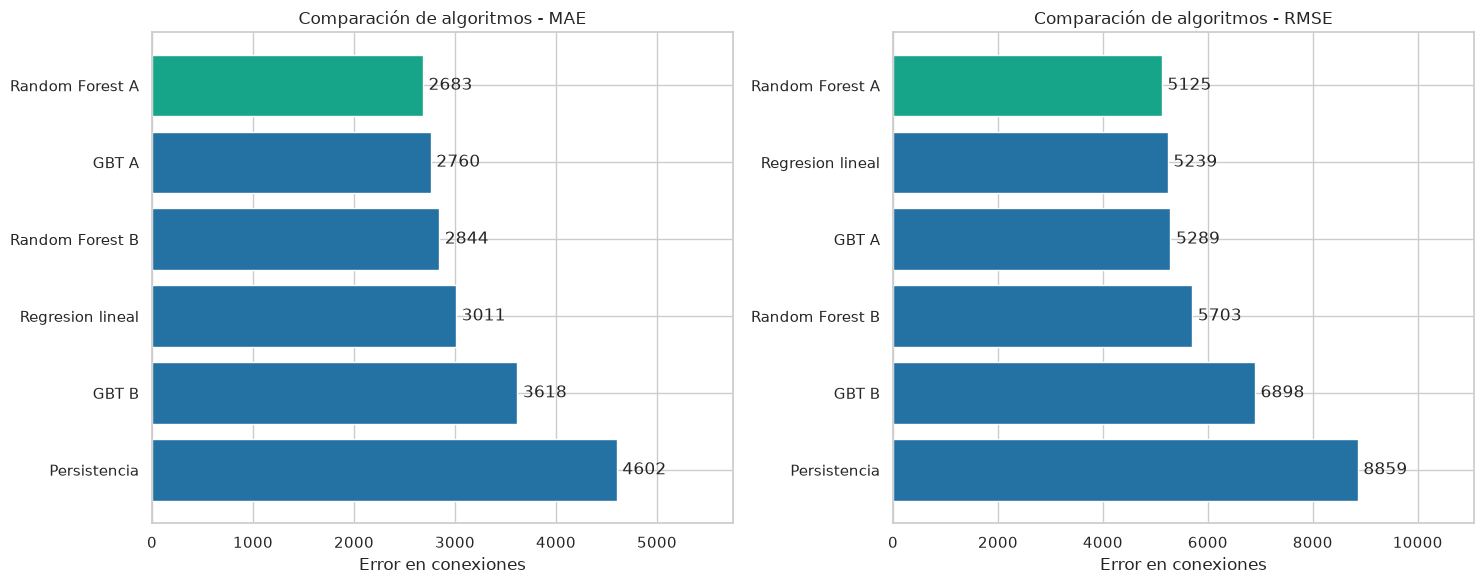

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(15, 6)
)

for ax, metrica in zip(axes, ["MAE", "RMSE"]):

    orden = tabla_modelos.sort_values(
        metrica, ascending=False
    )

    colores = [
        "#17A589"
        if v == orden[metrica].min()
        else "#2471A3"
        for v in orden[metrica]
    ]

    barras = ax.barh(
        orden["Modelo"],
        orden[metrica],
        color=colores
    )

    ax.bar_label(
        barras,
        fmt="%.0f",
        padding=4
    )

    ax.set_title(
        f"Comparación de algoritmos - {metrica}"
    )

    ax.set_xlabel("Error en conexiones")

    ax.set_xlim(
        0, orden[metrica].max() * 1.25
    )

plt.tight_layout()

plt.savefig(
    RESULTADOS / "01_comparacion_algoritmos.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Interpretación y selección del modelo

Random Forest A obtuvo el mejor desempeño durante la validación de 2024, alcanzando un MAE de 2.682,68 conexiones y un RMSE de 5.124,83 conexiones.

En comparación con la regresión lineal, el error absoluto promedio disminuyó un 10,90 %, mientras que frente al método de persistencia se obtuvo una reducción del 41,71 %.

La configuración seleccionada utiliza 50 árboles y una profundidad máxima de 3. Las configuraciones de mayor complejidad no consiguieron mejorar estos resultados.

Por lo tanto, se selecciona Random Forest A según el criterio establecido de menor MAE

In [8]:
seleccionado = "Random Forest A"

entrenamiento_final = entrenamiento.unionByName(validacion)

train_final_ml = assembler.transform(
    entrenamiento_final
).cache()

test_ml = assembler.transform(prueba).cache()

print("Modelo seleccionado:", seleccionado)
print("Observaciones de entrenamiento:", train_final_ml.count())
print("Observaciones de prueba:", test_ml.count())

modelo_final = candidatos[seleccionado].fit(
    train_final_ml
)

modelo_base_final = candidatos["Regresion lineal"].fit(
    train_final_ml
)

def predecir(modelo, datos):

    return (
        modelo.transform(datos)
        .withColumn(
            "prediccion",
            F.greatest(
                F.lit(0.0),
                F.col("conexiones")
                + F.col("variacion_predicha")
            )
        )
    )

pred_final = predecir(modelo_final, test_ml)

pred_base = predecir(modelo_base_final, test_ml)

pred_persistencia = prueba.withColumn(
    "prediccion",
    F.col("conexiones").cast("double")
)

metricas_finales = pd.DataFrame([
    evaluar("Persistencia", pred_persistencia),
    evaluar("Regresion lineal", pred_base),
    evaluar(seleccionado, pred_final)
])

display(metricas_finales.round(4))

metricas_finales.to_csv(
    RESULTADOS / "metricas_prueba_final.csv",
    index=False
)

Modelo seleccionado: Random Forest A
Observaciones de entrenamiento: 775
Observaciones de prueba: 125


,Modelo,MAE,RMSE,R2,WAPE_pct
0,Persistencia,4919.6720,7867.7283,0.9996,2.9148
1,Regresion lineal,4255.1590,8404.7412,0.9996,2.5211
2,Random Forest A,3874.6019,8039.9723,0.9996,2.2956


In [9]:
def detalle_predicciones(nombre, df):

    return (
        df.select(
            "departamento",
            "periodo",
            "periodo_objetivo",
            "conexiones",
            "conexiones_objetivo",
            "prediccion"
        )
        .withColumn("modelo", F.lit(nombre))
        .withColumn(
            "error",
            F.col("prediccion") - F.col("conexiones_objetivo")
        )
        .withColumn(
            "error_absoluto",
            F.abs(F.col("error"))
        )
        .toPandas()
    )

detalle = pd.concat([
    detalle_predicciones("Persistencia", pred_persistencia),
    detalle_predicciones("Regresion lineal", pred_base),
    detalle_predicciones(seleccionado, pred_final)
], ignore_index=True)

errores_trimestre = (
    detalle.groupby(["modelo", "periodo_objetivo"])
    .agg(
        MAE=("error_absoluto", "mean"),
        error_total=("error_absoluto", "sum"),
        conexiones_reales=("conexiones_objetivo", "sum"),
        conexiones_predichas=("prediccion", "sum")
    )
    .reset_index()
)

errores_trimestre["WAPE_pct"] = (
    errores_trimestre["error_total"]
    / errores_trimestre["conexiones_reales"]
) * 100

detalle_final = detalle[
    detalle["modelo"] == seleccionado
].copy()

errores_departamento = (
    detalle_final.groupby("departamento")
    .agg(
        MAE=("error_absoluto", "mean"),
        error_total=("error_absoluto", "sum"),
        conexiones_reales=("conexiones_objetivo", "sum")
    )
    .reset_index()
)

errores_departamento["WAPE_pct"] = (
    errores_departamento["error_total"]
    / errores_departamento["conexiones_reales"]
) * 100

errores_departamento = errores_departamento.sort_values(
    "WAPE_pct", ascending=False
)

print("ERRORES POR TRIMESTRE")

display(errores_trimestre.round(2))

print("ERRORES POR DEPARTAMENTO - RANDOM FOREST A")

display(errores_departamento.round(2))

detalle.to_csv(
    RESULTADOS / "predicciones_prueba.csv",
    index=False
)

errores_trimestre.to_csv(
    RESULTADOS / "errores_por_trimestre.csv",
    index=False
)

errores_departamento.to_csv(
    RESULTADOS / "errores_por_departamento.csv",
    index=False
)

ERRORES POR TRIMESTRE


,modelo,periodo_objetivo,MAE,error_total,conexiones_reales,conexiones_predichas,WAPE_pct
0,Persistencia,2025-03,3566.28,89157.00,4098323,4014572.00,2.18
1,Persistencia,2025-06,3843.16,96079.00,4194402,4098323.00,2.29
2,Persistencia,2025-09,3808.08,95202.00,4289604,4194402.00,2.22
3,Persistencia,2025-12,3597.60,89940.00,4379544,4289604.00,2.05
4,Persistencia,2026-03,9783.24,244581.00,4135995,4379544.00,5.91
5,Random Forest A,2025-03,1453.44,36336.06,4098323,4091358.63,0.89
6,Random Forest A,2025-06,1865.81,46645.20,4194402,4194631.61,1.11
7,Random Forest A,2025-09,1470.34,36758.61,4289604,4286452.14,0.86
8,Random Forest A,2025-12,1244.40,31109.88,4379544,4377374.25,0.71
9,Random Forest A,2026-03,13339.02,333475.48,4135995,4469470.48,8.06


ERRORES POR DEPARTAMENTO - RANDOM FOREST A


,departamento,MAE,error_total,conexiones_reales,WAPE_pct
24,UCAYALI,8489.36,42446.78,372331,11.40
17,MOQUEGUA,3423.96,17119.82,159358,10.74
23,TUMBES,4973.78,24868.88,236942,10.50
18,PASCO,842.12,4210.60,49884,8.44
15,LORETO,2962.74,14813.69,210817,7.03
2,APURIMAC,1536.80,7684.00,111174,6.91
9,HUANUCO,3504.64,17523.19,286433,6.12
8,HUANCAVELICA,705.89,3529.45,60872,5.80
21,SAN MARTIN,3217.71,16088.55,300392,5.36
10,ICA,8097.24,40486.22,812579,4.98


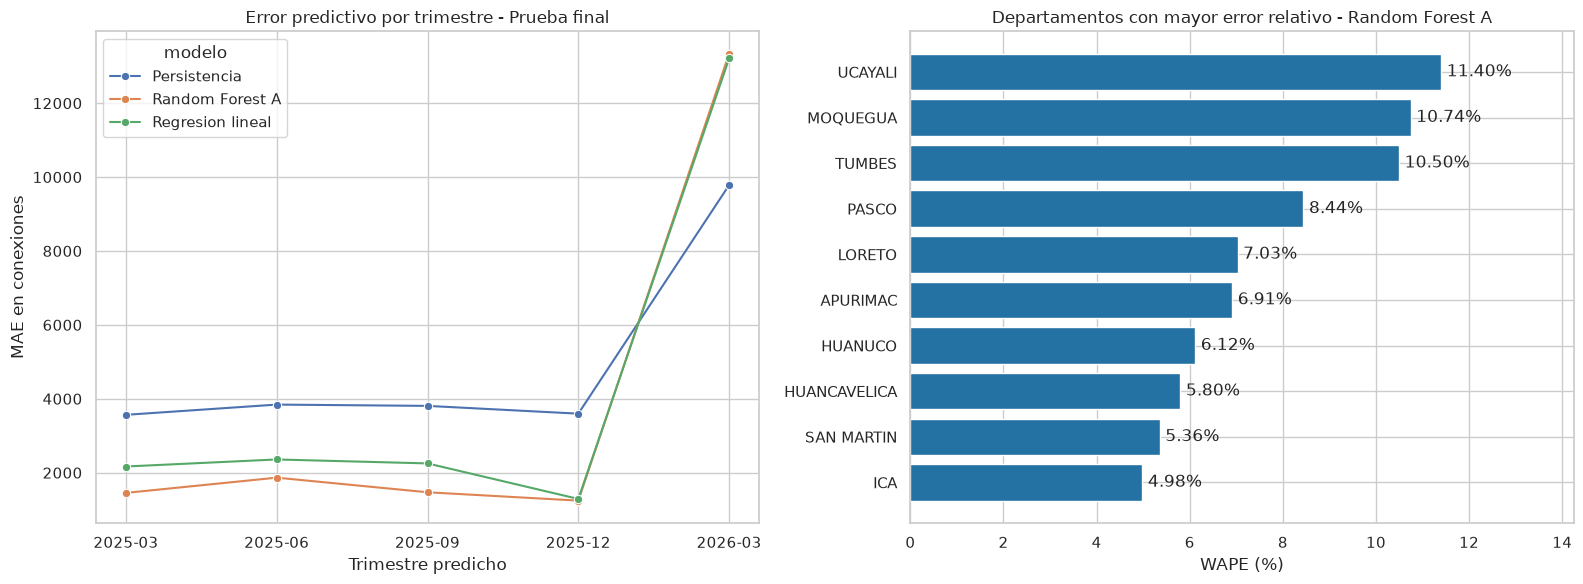

In [10]:
fig, axes = plt.subplots(
    1, 2, figsize=(16, 6)
)

sns.lineplot(
    data=errores_trimestre,
    x="periodo_objetivo",
    y="MAE",
    hue="modelo",
    marker="o",
    ax=axes[0]
)

axes[0].set_title(
    "Error predictivo por trimestre - Prueba final"
)

axes[0].set_xlabel("Trimestre predicho")
axes[0].set_ylabel("MAE en conexiones")

top_errores = (
    errores_departamento
    .head(10)
    .sort_values("WAPE_pct")
)

barras = axes[1].barh(
    top_errores["departamento"],
    top_errores["WAPE_pct"],
    color="#2471A3"
)

axes[1].bar_label(
    barras,
    fmt="%.2f%%",
    padding=4
)

axes[1].set_title(
    "Departamentos con mayor error relativo - Random Forest A"
)

axes[1].set_xlabel("WAPE (%)")

axes[1].set_xlim(
    0, top_errores["WAPE_pct"].max() * 1.25
)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "02_errores_prueba_final.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Interpretación de la prueba final

Random Forest A obtuvo un MAE general aproximado de 3.874,60 conexiones durante el periodo de prueba, superando a la regresión lineal y al método de persistencia.

Durante los cuatro trimestres de 2025, el modelo presentó errores relativos inferiores al 1,12 %. Sin embargo, en marzo de 2026 el WAPE aumentó al 8,06 %, debido a que el modelo no consiguió anticipar la disminución de conexiones reportadas durante dicho periodo.

Respecto al análisis territorial, Ucayali, Moquegua y Tumbes presentaron los mayores errores relativos, con valores de 11,40 %, 10,74 % y 10,50 %, respectivamente. Por otro lado, Lima y Callao presentaron errores relativos inferiores al 1 %.

Los resultados muestran que el modelo puede utilizarse como referencia para estimar la evolución trimestral de las conexiones fijas. Sin embargo, presenta limitaciones ante cambios abruptos que no se encuentran representados en las variables históricas.

Por ello, las predicciones deben complementarse con el seguimiento de operadores, tecnologías y reportes estadísticos, evitando utilizarlas como único criterio para la toma de decisiones.

In [11]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import SQLTransformer

MODELOS = PROYECTO / "models"
MODELOS.mkdir(parents=True, exist_ok=True)

ajuste_prediccion = SQLTransformer(
    statement="""
        SELECT *,
        GREATEST(
            CAST(0 AS DOUBLE),
            conexiones + variacion_predicha
        ) AS prediccion
        FROM __THIS__
    """
)

pipeline_evaluado = PipelineModel(
    stages=[
        assembler,
        modelo_final,
        ajuste_prediccion
    ]
)

pipeline_evaluado.write().overwrite().save(
    (MODELOS / "random_forest_evaluado").as_uri()
)

pipeline_operativo = Pipeline(
    stages=[
        assembler,
        candidatos[seleccionado],
        ajuste_prediccion
    ]
)

modelo_operativo = pipeline_operativo.fit(
    datos_supervisados
)

modelo_operativo.write().overwrite().save(
    (MODELOS / "random_forest_operativo").as_uri()
)

print("Modelo evaluado guardado correctamente")
print("Modelo operativo guardado correctamente")
print("Directorio:", MODELOS)

Modelo evaluado guardado correctamente
Modelo operativo guardado correctamente
Directorio: /home/nevado/BigData_UPAO/bigdata-osiptel-brecha-digital/models


In [12]:
ultimo_periodo = panel.agg(
    F.max("periodo")
).first()[0]

datos_prediccion = (
    datos_modelo
    .filter(F.col("periodo") == ultimo_periodo)
    .dropna(subset=features)
    .drop(
        "periodo_objetivo",
        "conexiones_objetivo",
        "variacion_objetivo"
    )
    .withColumn(
        "periodo_prediccion",
        F.date_format(
            F.add_months(
                F.to_date(
                    F.concat(
                        F.col("periodo"),
                        F.lit("-01")
                    )
                ),
                3
            ),
            "yyyy-MM"
        )
    )
)

modelo_cargado = PipelineModel.load(
    (MODELOS / "random_forest_operativo").as_uri()
)

proyecciones = (
    modelo_cargado.transform(datos_prediccion)

    .withColumn(
        "variacion_estimada",
        F.col("prediccion") - F.col("conexiones")
    )

    .withColumn(
        "variacion_estimada_pct",
        F.when(
            F.col("conexiones") > 0,
            F.col("variacion_estimada")
            / F.col("conexiones") * 100
        )
    )

    .select(
        "departamento",
        "periodo",
        "periodo_prediccion",
        "conexiones",
        "prediccion",
        "variacion_estimada",
        "variacion_estimada_pct"
    )

    .orderBy("variacion_estimada_pct")
    .toPandas()
)

display(proyecciones.round(2))

proyecciones.to_csv(
    RESULTADOS / "prediccion_siguiente_trimestre.csv",
    index=False
)

print("Territorios predichos:", len(proyecciones))

print(
    "Total nacional estimado:",
    round(proyecciones["prediccion"].sum())
)

,departamento,periodo,periodo_prediccion,conexiones,prediccion,variacion_estimada,variacion_estimada_pct
0,LIMA,2026-03,2026-06,2130340,2142227.23,11887.23,0.56
1,CALLAO,2026-03,2026-06,167774,169468.90,1694.90,1.01
2,ANCASH,2026-03,2026-06,111981,116633.70,4652.70,4.15
3,MADRE DE DIOS,2026-03,2026-06,15593,16383.81,790.81,5.07
4,PIURA,2026-03,2026-06,178221,187646.93,9425.93,5.29
5,ICA,2026-03,2026-06,146878,154788.07,7910.07,5.39
6,CAJAMARCA,2026-03,2026-06,64630,68184.88,3554.88,5.50
7,CUSCO,2026-03,2026-06,106695,112613.44,5918.44,5.55
8,LA LIBERTAD,2026-03,2026-06,227841,241035.36,13194.36,5.79
9,AMAZONAS,2026-03,2026-06,13008,13764.32,756.32,5.81


Territorios predichos: 25
Total nacional estimado: 4276082


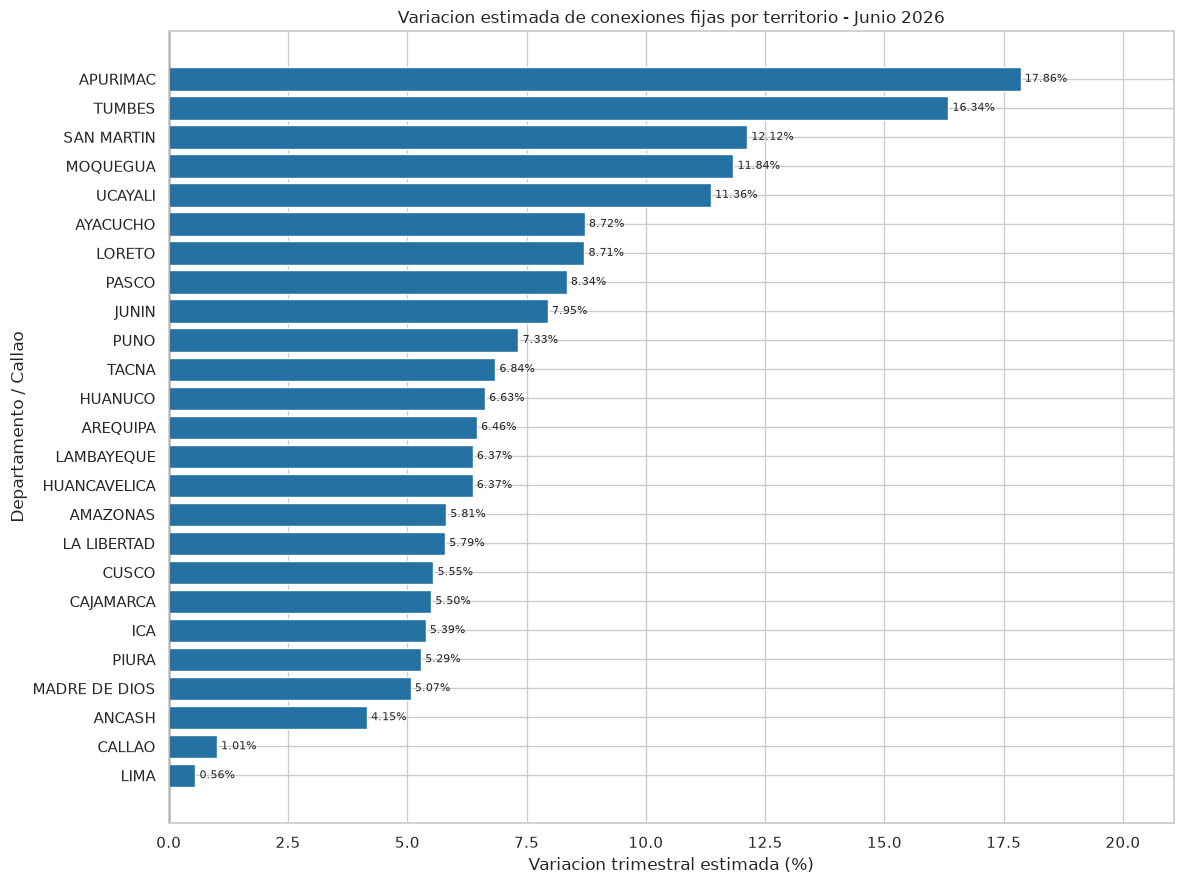

In [13]:
orden = proyecciones.sort_values(
    "variacion_estimada_pct"
)

colores = [
    "#C0392B" if v < 0 else "#2471A3"
    for v in orden["variacion_estimada_pct"]
]

plt.figure(figsize=(12, 9))

barras = plt.barh(
    orden["departamento"],
    orden["variacion_estimada_pct"],
    color=colores
)

plt.bar_label(
    barras,
    fmt="%.2f%%",
    padding=3,
    fontsize=8
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Variacion estimada de conexiones fijas por territorio - Junio 2026"
)

plt.xlabel("Variacion trimestral estimada (%)")
plt.ylabel("Departamento / Callao")
plt.margins(x=0.18)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "03_prediccion_territorial.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()